# Digital Image Processing (DIP) - Section 2
## Low-Level Pixel Processing Using Nested FOR Loops

### 🎯 Learning Objectives
1. **Image Representation:** Understand how computers store images as multi-dimensional matrices.
2. **Pixel Inspection:** Read coordinates and individual RGB color channels `(R, G, B)`.
3. **Manual Grayscale Conversion:** Convert a 3-channel RGB image to a 1-channel luminance matrix using nested loops without external library shortcuts.
4. **Manual Binarization (Thresholding):** Segment a grayscale image into black (0) and white (255) pixels based on an intensity threshold $T$.

---
## 1. Read and Display Image

### 📦 Imported Libraries:
- **`from PIL import Image` (Pillow):**
  - **What it is:** Python Imaging Library (Pillow) is the standard library for opening, decoding, and manipulating raster image files (`.png`, `.jpg`, `.bmp`, etc.).
  - **Role in DIP:** Digital image files are encoded/compressed on the hard drive. PIL reads the raw file bytes, decodes the image compression, and loads the image into memory as a manipulable image object.
- **`import numpy as np`:**
  - **What it is:** The foundational library for multidimensional arrays, matrices, and linear algebra in Python.
  - **Role in DIP:** Mathematically, a digital image is a 2D or 3D numerical matrix. NumPy allows us to treat pixels as numbers ($0–255$ of type `uint8`), access coordinates via matrix indexing `img[row, col]`, and perform mathematical pixel transformations.
- **`import matplotlib.pyplot as plt`:**
  - **What it is:** A 2D plotting and data visualization library modeled after MATLAB.
  - **Role in DIP:** Renders numerical matrices visually on the screen (`plt.imshow()`), controls colormaps (e.g., `cmap="gray"`), and configures titles and axes (`plt.axis("off")`).

### 🖼️ Display Commands Explanation:
- **`plt.imshow(image)`:** Renders and maps the pixel matrix coordinates $(x, y)$ and $(R, G, B)$ values onto an internal 2D drawing canvas buffer.
- **`plt.title("Original Image")`:** Places a descriptive text title above the canvas so the viewer can identify the image state.
- **`plt.axis("off")`:** Hides the graph tick marks, coordinate borders, and grid numbers to display a clean photographic image rather than a chart with axes.
- **`plt.show()`:** Flushes the figure buffer and displays the image window on the screen (or inline within the notebook).

### 📘 Theoretical Description:
- **Digital Image as a Matrix:** A continuous physical image $f(x, y)$ is sampled into a 2D discrete grid of $M$ rows and $N$ columns, and quantized into discrete intensity levels $L = 2^k$ (for 8-bit images, $k=8 \implies L=256$, levels $0$ to $255$).
- **RGB Color Model:** Based on the **Trichromatic Theory** of human vision (S, M, and L cones). An RGB image is a vector-valued 2D function:
  $$\mathbf{f}(i, j) = \begin{bmatrix} R(i, j) \\ G(i, j) \\ B(i, j) \end{bmatrix} \in [0, 255]^3$$
- **`.convert("RGB")`:** Standardizes the image to 3 channels (Red, Green, Blue), discarding unnecessary alpha (transparency) channels or color palette lookups.
- **NumPy Shape `(height, width, channels)`:**
  - `height` ($M$): Number of pixel rows along the vertical axis.
  - `width` ($N$): Number of pixel columns along the horizontal axis.
  - `channels`: 3 spectral color bands ($0 = \text{Red}, 1 = \text{Green}, 2 = \text{Blue}$).


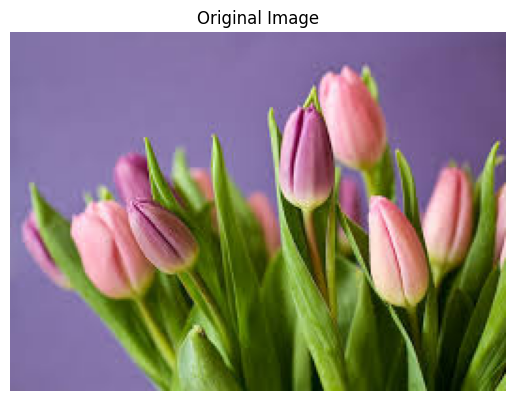

Image Height: 359
Image Width : 496
Channels    : 3


In [1]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------
# 1. Read and Display Image
# ------------------------------------------------

image = Image.open("image.png").convert("RGB")

plt.imshow(image)
plt.title("Original Image")
plt.axis("off")
plt.show()


# Convert image to NumPy array
img = np.array(image)

height, width, channels = img.shape

print("Image Height:", height)
print("Image Width :", width)
print("Channels    :", channels)


---
## 2. Display Pixel Values

### 📘 Theoretical Description:
- **Discrete Spatial Indexing:** In Digital Image Processing, pixels are referenced via matrix coordinates $(i, j)$:
  - $i$ is the row index (vertical position, from top to bottom, $0 \le i < M$).
  - $j$ is the column index (horizontal position, from left to right, $0 \le j < N$).
- **Tristimulus Vector:** `img[i, j]` yields a 3-element vector `[R, G, B]`, representing the quantized photon intensity captured at that spatial position.
- **`min(5, height)` / `min(5, width)`:** Safeguard boundary checks ensuring that loops do not exceed image dimensions when sampling the top-left $5 \times 5$ neighborhood.


In [2]:
# ------------------------------------------------
# 2. Display Pixel Values
# ------------------------------------------------

print("\nFirst 5 x 5 pixels:")

for i in range(min(5, height)):
    for j in range(min(5, width)):
        print(f"pixel[{i},{j}] = {img[i,j]}")



First 5 x 5 pixels:
pixel[0,0] = [128 114 167]
pixel[0,1] = [128 114 167]
pixel[0,2] = [128 114 167]
pixel[0,3] = [128 114 167]
pixel[0,4] = [128 114 167]
pixel[1,0] = [128 114 167]
pixel[1,1] = [128 114 167]
pixel[1,2] = [128 114 167]
pixel[1,3] = [128 114 167]
pixel[1,4] = [128 114 167]
pixel[2,0] = [128 114 167]
pixel[2,1] = [128 114 167]
pixel[2,2] = [128 114 167]
pixel[2,3] = [128 114 167]
pixel[2,4] = [128 114 167]
pixel[3,0] = [128 114 167]
pixel[3,1] = [128 114 167]
pixel[3,2] = [128 114 167]
pixel[3,3] = [128 114 167]
pixel[3,4] = [128 114 167]
pixel[4,0] = [128 114 167]
pixel[4,1] = [128 114 167]
pixel[4,2] = [128 114 167]
pixel[4,3] = [128 114 167]
pixel[4,4] = [128 114 167]


---
## 3. Convert RGB Image to Grayscale

### 📘 Theoretical Description:
- **Luminance vs. Simple Average:**
  A naive average $\frac{R + G + B}{3}$ fails to represent perceived brightness because human eye cone cells do not respond uniformly to all light wavelengths (**Photopic Luminous Efficiency**).
- **The Standard Luminance Equation (ITU-R BT.601 / CIE):**
  $$Y = 0.299 \times R + 0.587 \times G + 0.114 \times B$$
  - **Green ($58.7\%$):** Highest perceived brightness and spatial detail sensitivity.
  - **Red ($29.9\%$):** Moderate perceived brightness.
  - **Blue ($11.4\%$):** Lowest contribution to luminance perception.
- **Weight Sum to Unity:** $0.299 + 0.587 + 0.114 = 1.0$. This ensures that pure white $[255, 255, 255]$ maps exactly to $255$.
- **`np.zeros((height, width), dtype=np.uint8)`:** Pre-allocates a 2D scalar field in memory ($8$ bits per pixel), reducing image storage by $66.7\%$ compared to 3-channel RGB.
- **`int()` Casting:** Prevents 8-bit unsigned integer overflow arithmetic ($255 + 1 = 0 \pmod{256}$) during calculations.
- **`cmap="gray"`:** In Matplotlib, 2D arrays default to the pseudocolor `viridis` colormap. `cmap="gray"` explicitly maps $0 \to \text{Black}$ and $255 \to \text{White}$.


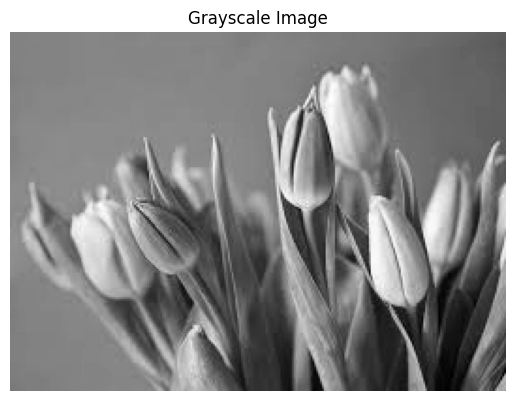

In [3]:
# ------------------------------------------------
# 3. Convert RGB Image to Grayscale
# ------------------------------------------------

gray = np.zeros((height, width), dtype=np.uint8)

for i in range(height):
    for j in range(width):

        R = int(img[i, j, 0])
        G = int(img[i, j, 1])
        B = int(img[i, j, 2])

        # Grayscale formula
        gray_value = int(0.299 * R + 0.587 * G + 0.114 * B)

        gray[i, j] = gray_value


plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")
plt.show()


---
## 4. Convert Grayscale to Binary (Thresholding / Segmentation)

### 📘 Theoretical Description:
- **Spatial Domain Point Operation:** Each output pixel depends only on the intensity at that exact coordinate:
  $$s = T(r)$$
- **Binarization Function:** Converts a multi-level gray image ($256$ intensity levels) into a 2-level binary mask:
  $$g(i, j) = \begin{cases} 255 & \text{if } f_{\text{gray}}(i, j) \ge T \\ 0 & \text{if } f_{\text{gray}}(i, j) < T \end{cases}$$
- **Global Threshold ($T = 128$):** The midpoint of the dynamic range $[0, 255]$.
  - Intensities $\ge 128$ are classified as **Foreground / Bright** ($255$, white).
  - Intensities $< 128$ are classified as **Background / Dark** ($0$, black).
- **Application in DIP:** Image segmentation, object shape extraction, edge enhancement, and character recognition (OCR).


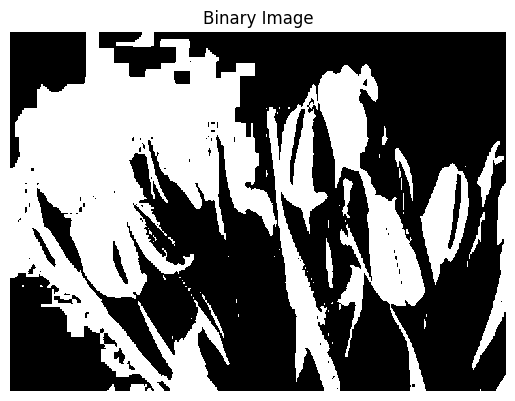

In [4]:
# ------------------------------------------------
# 4. Convert Grayscale to Binary
# ------------------------------------------------

threshold = 128

binary = np.zeros((height, width), dtype=np.uint8)

for i in range(height):
    for j in range(width):

        if gray[i, j] >= threshold:
            binary[i, j] = 255
        else:
            binary[i, j] = 0


plt.imshow(binary, cmap="gray")
plt.title("Binary Image")
plt.axis("off")
plt.show()


---
## 5. Visual Summary: Side-by-Side Comparison
Comparing the 3 stages of data reduction:
1. **RGB Color:** 24 bits/pixel, continuous color tones.
2. **Grayscale:** 8 bits/pixel, monochromatic luminance gradient.
3. **Binary:** 1 bit/pixel equivalent, discrete shape segmentation.


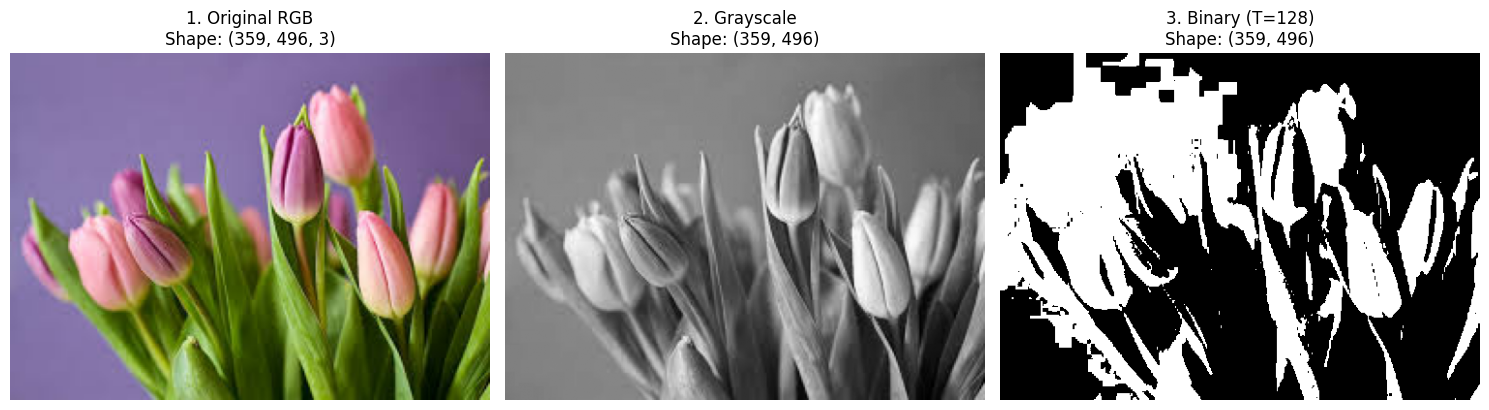

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img)
axes[0].set_title(f"1. Original RGB\nShape: {img.shape}")
axes[0].axis("off")

axes[1].imshow(gray, cmap="gray")
axes[1].set_title(f"2. Grayscale\nShape: {gray.shape}")
axes[1].axis("off")

axes[2].imshow(binary, cmap="gray")
axes[2].set_title(f"3. Binary (T={threshold})\nShape: {binary.shape}")
axes[2].axis("off")

plt.tight_layout()
plt.show()
